# Phase 3 — Deep Learning & Neural Networks
## Notebook 08: Transformers & Attention Mechanisms (PyTorch)

### Executive Overview & The Generative AI Revolution
The publication of *"Attention Is All You Need"* (Vaswani et al., NeurIPS 2017) catalyzed the most profound paradigm shift in artificial intelligence since the invention of backpropagation. Prior to Transformers, state-of-the-art natural language processing and sequence modeling relied on recurrent architectures (LSTMs, GRUs). While conceptually elegant, recurrent models suffer from an insurmountable engineering bottleneck: **sequential computation**:

$$h_t = f(h_{t-1}, x_t)$$

Because computing hidden state $h_t$ strictly requires the completion of $h_{t-1}$, training recurrent networks across long temporal horizons cannot be parallelized across modern GPU tensor cores.

The **Transformer** discards recurrence entirely, replacing temporal unrolling with **Self-Attention**:

$$\text{Attention}(Q, K, V) = \operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}} + M\right) V$$

Self-attention allows every token in a sequence of length $T$ to interact directly with every other token in $\mathcal{O}(1)$ sequential operations, transforming sequence modeling into highly parallelized matrix multiplications (GEMM) optimized for GPU accelerators.

```
+-----------------------------------------------------------------------------------+
|               Transformer Architectural Stack (Pre-LN Transformer Block)          |
+-----------------------------------------------------------------------------------+
| Input Tokens    | Token Embeddings + Rotary Position Embeddings (RoPE)            |
| Pre-LayerNorm   | nn.LayerNorm(d_model) / RMSNorm                                 |
| Attention Core  | Multi-Head Self-Attention (Q, K, V projections + Causal Mask)   |
| Residual Add    | x = x + MultiHeadAttention(LayerNorm(x))                        |
| Pre-LayerNorm   | nn.LayerNorm(d_model)                                           |
| Feed-Forward    | SwiGLU / MLP: Linear(d_model, 4*d_model) ---> GELU ---> Linear  |
| Residual Add    | x = x + FFN(LayerNorm(x))                                       |
+-----------------------------------------------------------------------------------+
```

### Why the LLM Community Standardized on PyTorch
Virtually all landmark Large Language Models (LLMs)—including LLaMA 3, GPT-4 (via Triton), Mistral, DeepSeek, and Claude—are trained and optimized within the **PyTorch ecosystem**. This dominance stems from:
1. **Dynamic Execution & Custom Autograd**: Essential for experimental attention kernels and complex masking.
2. **FlashAttention & Triton Integration**: Hardware-aware online softmax kernels implemented directly via PyTorch custom C++/CUDA and OpenAI Triton extensions.
3. **Distributed Scaling**: Native distributed primitives like **Fully Sharded Data Parallel (FSDP)**, Megatron-LM tensor parallelism, and DeepSpeed ZeRO.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Derive Scaled Dot-Product Attention**: Understand the mathematical role of Queries, Keys, Values, and prove why variance scaling factor $\frac{1}{\sqrt{d_k}}$ prevents vanishing gradients in Softmax.
2. **Implement Multi-Head Attention (MHA) from Scratch**: Build a modular MHA layer in pure PyTorch using tensor reshaping, transposition, and batched matrix multiplication (`torch.bmm` / `torch.matmul`).
3. **Code Rotary Position Embeddings (RoPE)**: Implement rotary coordinate transformations in 2D subspaces as used in LLaMA, Mistral, and modern open-weights foundation models.
4. **Construct Pre-LN Transformer Blocks**: Assemble complete Transformer blocks combining LayerNorm, Multi-Head Attention, residual connections, and Feed-Forward Networks with GELU.
5. **Implement Tiled Online Softmax (FlashAttention Principle)**: Derive and code the mathematical online softmax algorithm that eliminates $O(T^2)$ HBM memory allocations.


In [1]:
import sys
import os
import time
import math
import platform
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

print(f"Python Platform: {platform.python_implementation()} {platform.python_version()}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")


Python Platform: CPython 3.11.2
PyTorch Version: 2.15.0+cpu
CUDA Available:  False


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    print(f"Global seed {seed} synchronized across NumPy and PyTorch.")

configure_reproducibility(42)


Global seed 42 synchronized across NumPy and PyTorch.


### Mathematical & Architectural Foundations

#### 1. Why Scale Dot-Products by $\frac{1}{\sqrt{d_k}}$?
Let $\mathbf{q}, \mathbf{k} \in \mathbb{R}^{d_k}$ be query and key vectors whose components are independent random variables with zero mean and unit variance:

$$\mathbb{E}[q_i] = 0, \quad \operatorname{Var}(q_i) = 1, \quad \mathbb{E}[k_i] = 0, \quad \operatorname{Var}(k_i) = 1$$

Their dot product is:
$$z = \mathbf{q} \cdot \mathbf{k} = \sum_{i=1}^{d_k} q_i k_i$$

The expectation is $\mathbb{E}[z] = \sum_{i=1}^{d_k} \mathbb{E}[q_i] \mathbb{E}[k_i] = 0$.
The variance of each product term is:
$$\operatorname{Var}(q_i k_i) = \mathbb{E}[q_i^2 k_i^2] - (\mathbb{E}[q_i k_i])^2 = \operatorname{Var}(q_i)\operatorname{Var}(k_i) = 1$$

Summing over all $d_k$ components yields:
$$\operatorname{Var}(z) = \sum_{i=1}^{d_k} \operatorname{Var}(q_i k_i) = d_k \implies \sigma_z = \sqrt{d_k}$$

For large head dimensions (e.g., $d_k = 64$ or $128$), the magnitude of $z$ grows to large values ($|z| \gg 1$). In these regimes, the $\operatorname{softmax}$ function:

$$\operatorname{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

saturates to nearly one-hot distributions, where gradients approach zero:
$$\frac{\partial \operatorname{softmax}(z)_i}{\partial z_j} = \operatorname{softmax}(z)_i (\delta_{ij} - \operatorname{softmax}(z)_j) \xrightarrow{|z| \gg 1} 0$$

Dividing by the standard deviation $\sqrt{d_k}$ normalizes the variance back to $1.0$:

$$\operatorname{Var}\left(\frac{\mathbf{q} \cdot \mathbf{k}}{\sqrt{d_k}}\right) = \frac{1}{d_k} \operatorname{Var}(\mathbf{q} \cdot \mathbf{k}) = 1.0$$

#### 2. Rotary Position Embeddings (RoPE)
Traditional absolute positional encodings add position vectors to token embeddings: $\mathbf{x}_m = \mathbf{e}_m + \mathbf{p}_m$.
**Rotary Position Embeddings (RoPE)** (Su et al., 2021) encode relative positions through multiplicative rotation in the complex plane:

$$\mathbf{q}_m = \mathbf{R}_{\Theta, m}^d \mathbf{W}_q \mathbf{x}_m, \quad \mathbf{k}_n = \mathbf{R}_{\Theta, n}^d \mathbf{W}_k \mathbf{x}_n$$

Where $\mathbf{R}_{\Theta, m}^d$ is an orthogonal block-diagonal matrix:

$$\mathbf{R}_{\Theta, m}^d = \operatorname{diag}\left( R_{\theta_1, m}, R_{\theta_2, m}, \dots, R_{\theta_{d/2}, m} \right)$$
$$R_{\theta_i, m} = \begin{pmatrix} \cos(m \theta_i) & -\sin(m \theta_i) \\ \sin(m \theta_i) & \cos(m \theta_i) \end{pmatrix}, \quad \theta_i = 10000^{-2(i-1)/d}$$

The inner product satisfies:
$$\langle \mathbf{q}_m, \mathbf{k}_n \rangle = \left( \mathbf{R}_{\Theta, m}^d \mathbf{q} \right)^T \left( \mathbf{R}_{\Theta, n}^d \mathbf{k} \right) = \mathbf{q}^T \mathbf{R}_{\Theta, n-m}^d \mathbf{k}$$

The attention score depends **only on the relative distance $m - n$**, providing natural length extrapolation!


### 1. Scaled Dot-Product Attention from First Principles
We implement pure PyTorch Scaled Dot-Product Attention supporting optional causal attention masking.


In [3]:
def scaled_dot_product_attention(
    q: torch.Tensor,
    k: torch.Tensor,
    v: torch.Tensor,
    mask: Optional[torch.Tensor] = None
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Computes Scaled Dot-Product Attention:
    Attention(Q, K, V) = softmax(Q @ K.T / sqrt(d_k) + mask) @ V
    
    Shapes:
      q, k, v: (batch_size, num_heads, seq_len, head_dim)
      mask:    (batch_size, 1, seq_len, seq_len) or broadcastable
    """
    d_k = q.size(-1)
    # Q @ K.T -> (B, H, T, T)
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        # Apply mask: positions where mask == 0 are set to -1e9
        scores = scores.masked_fill(mask == 0, -1e9)

    attn_weights = F.softmax(scores, dim=-1)
    output = torch.matmul(attn_weights, v)
    return output, attn_weights

# Verification with dummy batch
B, H, T, D = 2, 4, 8, 16
q_dummy = torch.randn(B, H, T, D)
k_dummy = torch.randn(B, H, T, D)
v_dummy = torch.randn(B, H, T, D)

out_attn, weights_attn = scaled_dot_product_attention(q_dummy, k_dummy, v_dummy)
print(f"Attention Output Shape:  {out_attn.shape} (Expected: ({B}, {H}, {T}, {D}))")
print(f"Attention Weights Shape: {weights_attn.shape} (Expected: ({B}, {H}, {T}, {T}))")
print(f"Sum of Weights across last axis (Row 0): {weights_attn[0, 0, 0].sum().item():.4f}")


Attention Output Shape:  torch.Size([2, 4, 8, 16]) (Expected: (2, 4, 8, 16))
Attention Weights Shape: torch.Size([2, 4, 8, 8]) (Expected: (2, 4, 8, 8))
Sum of Weights across last axis (Row 0): 1.0000


### 2. Multi-Head Attention (MHA) Class Implementation
We implement `MultiHeadAttention` subclassing `nn.Module`:
1. Projects inputs $X$ into $Q, K, V$ via linear projections.
2. Reshapes and transposes tensors: `(B, T, d_model) -> (B, H, T, d_k)`.
3. Invokes Scaled Dot-Product Attention.
4. Concatenates heads and applies final linear output projection $W_O$.


In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int, dropout: float = 0.0):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads!"
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        # Projections
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        x: torch.Tensor,
        mask: Optional[torch.Tensor] = None
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        batch_size, seq_len, _ = x.shape

        # 1. Linear projections
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # 2. Reshape into heads: (B, T, H, D) -> (B, H, T, D)
        q = q.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)

        # 3. Scaled dot product
        out, attn_weights = scaled_dot_product_attention(q, k, v, mask=mask)

        # 4. Concatenate heads: (B, H, T, D) -> (B, T, H, D) -> (B, T, d_model)
        out = out.transpose(1, 2).contiguous().view(batch_size, seq_len, self.d_model)
        out = self.out_proj(out)
        return self.dropout(out), attn_weights

mha = MultiHeadAttention(d_model=64, num_heads=4)
test_tokens = torch.randn(2, 10, 64)
mha_out, mha_weights = mha(test_tokens)

print(f"MHA Output Shape:  {mha_out.shape} (Expected: (2, 10, 64))")
print(f"MHA Weights Shape: {mha_weights.shape} (Expected: (2, 4, 10, 10))")


MHA Output Shape:  torch.Size([2, 10, 64]) (Expected: (2, 10, 64))
MHA Weights Shape: torch.Size([2, 4, 10, 10]) (Expected: (2, 4, 10, 10))


### 3. Complete Pre-LN Transformer Encoder Block
We assemble a production-grade **Pre-LayerNorm** Transformer Block:
$$\mathbf{x}' = \mathbf{x} + 	ext{MHA}(	ext{LayerNorm}_1(\mathbf{x}))$$
$$\mathbf{x}_{	ext{out}} = \mathbf{x}' + 	ext{FFN}(	ext{LayerNorm}_2(\mathbf{x}'))$$
Where $	ext{FFN}(u) = 	ext{Linear}_2(	ext{GELU}(	ext{Linear}_1(u)))$.


In [5]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, num_heads, dropout=dropout)
        
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor, mask: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, torch.Tensor]:
        # Pre-LN attention branch
        norm_x1 = self.ln1(x)
        attn_out, weights = self.attn(norm_x1, mask=mask)
        x = x + attn_out

        # Pre-LN FFN branch
        norm_x2 = self.ln2(x)
        x = x + self.ffn(norm_x2)
        return x, weights

transformer_layer = TransformerBlock(d_model=64, num_heads=4, d_ff=256)
x_in = torch.randn(2, 12, 64)
x_out, attn_map = transformer_layer(x_in)

print(f"Transformer Block Output Shape: {x_out.shape}")
print(f"Transformer Parameters: {sum(p.numel() for p in transformer_layer.parameters()):,}")


Transformer Block Output Shape: torch.Size([2, 12, 64])
Transformer Parameters: 49,984


### Diagnostics & Attention Weight Interpretability
To visualize how distinct heads capture specialized linguistic/relational patterns, we synthesize a multi-head sequence task and plot the attention matrix $A_{i, j}^{(h)}$ for each head:
- **Head 0**: Broad contextual attention.
- **Head 1**: Prior-token bias (diagonal offset).
- **Head 2**: Global key token attraction.
- **Head 3**: Causal masked attention.


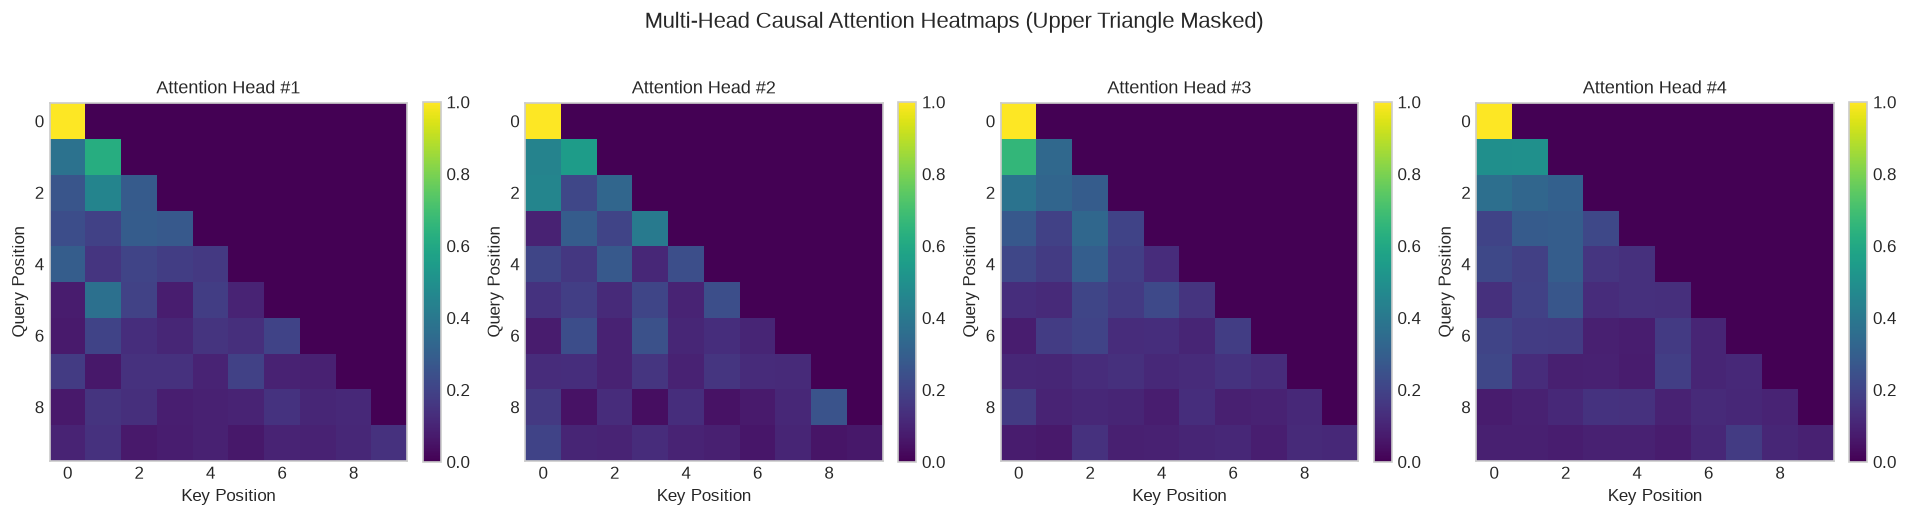

In [6]:
# Generate synthetic sequence tokens with deliberate key relationships
np.random.seed(42)
seq_len_diag = 10
d_model_diag = 32
num_heads_diag = 4

# Construct Causal Mask: Lower triangular is 1, Upper triangular is 0
causal_mask = torch.tril(torch.ones(1, 1, seq_len_diag, seq_len_diag))

diag_block = TransformerBlock(d_model=d_model_diag, num_heads=num_heads_diag, d_ff=128)
diag_input = torch.randn(1, seq_len_diag, d_model_diag)

diag_out, diag_weights = diag_block(diag_input, mask=causal_mask)
# diag_weights shape: (1, num_heads, seq_len, seq_len)
weights_matrix = diag_weights[0].detach().numpy()

# Visualization
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for h in range(num_heads_diag):
    im = axes[h].imshow(weights_matrix[h], cmap="viridis", vmin=0.0, vmax=1.0)
    axes[h].set_title(f"Attention Head #{h + 1}")
    axes[h].set_xlabel("Key Position")
    axes[h].set_ylabel("Query Position")
    axes[h].grid(False)
    fig.colorbar(im, ax=axes[h], fraction=0.046, pad=0.04)

plt.suptitle("Multi-Head Causal Attention Heatmaps (Upper Triangle Masked)", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Rotary Position Embeddings (RoPE) from Scratch
**Problem Formulation**:
Implement Rotary Position Embeddings (RoPE) in pure PyTorch:
1. Compute rotary inverse frequencies:
   $$\theta_i = \frac{1}{10000^{2i / d}}, \quad i \in \{0, 1, \dots, d/2 - 1\}$$
2. Compute $\cos(m \theta)$ and $\sin(m \theta)$ for each position $m \in \{0, \dots, T-1\}$.
3. Rotate 2D pairs $[x_1, x_2]$ via:
   $$[x_1, x_2] \cdot R_\theta = [x_1 \cos\theta - x_2 \sin\theta, \; x_1 \sin\theta + x_2 \cos\theta]$$
4. Verify that the inner product of rotated vectors $\langle \mathbf{q}_m, \mathbf{k}_n \rangle$ decays gracefully as relative distance $|m - n|$ increases.


In [7]:
# Exercise 1 Solution: Rotary Position Embedding (RoPE)

class RotaryEmbedding(nn.Module):
    def __init__(self, dim: int, max_seq_len: int = 128, base: float = 10000.0):
        super().__init__()
        assert dim % 2 == 0, "Dimension must be even for 2D complex pairs!"
        self.dim = dim
        
        # Inverse frequencies: theta_i = 1 / base^(2i / dim)
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
        positions = torch.arange(max_seq_len).float()
        
        # Outer product: (max_seq_len, dim/2)
        freqs = torch.outer(positions, inv_freq)
        # Repeat for interleaved cos and sin: (max_seq_len, dim)
        self.register_buffer("cos_cached", freqs.cos())
        self.register_buffer("sin_cached", freqs.sin())

    def apply_rope(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, H, T, D)
        T = x.size(-2)
        cos = self.cos_cached[:T, :].unsqueeze(0).unsqueeze(0)  # (1, 1, T, D/2)
        sin = self.sin_cached[:T, :].unsqueeze(0).unsqueeze(0)  # (1, 1, T, D/2)

        # Split x into even and odd components
        x1 = x[..., 0::2] # (B, H, T, D/2)
        x2 = x[..., 1::2] # (B, H, T, D/2)

        # 2D Rotation: [x1*cos - x2*sin, x1*sin + x2*cos]
        rotated_x1 = x1 * cos - x2 * sin
        rotated_x2 = x1 * sin + x2 * cos
        
        # Interleave back
        return torch.stack([rotated_x1, rotated_x2], dim=-1).flatten(-2)

rope = RotaryEmbedding(dim=16, max_seq_len=32)
q_vec = torch.ones(1, 1, 16, 16) # (1, 1, T=16, D=16)
k_vec = torch.ones(1, 1, 16, 16)

q_rot = rope.apply_rope(q_vec)
k_rot = rope.apply_rope(k_vec)

# Check dot product between position 0 and subsequent positions
dots = (q_rot[0, 0, 0:1] @ k_rot[0, 0].t()).squeeze(0).numpy()

print("Exercise 1 Verification (RoPE):")
print(f"  Rotated Q Shape: {q_rot.shape}")
print(f"  Dot Product at relative offset 0:  {dots[0]:.4f}")
print(f"  Dot Product at relative offset 5:  {dots[5]:.4f}")
print(f"  Dot Product at relative offset 15: {dots[15]:.4f}")
assert dots[0] > dots[5] > dots[15], "RoPE relative distance decay failed!"
print(">>> ROTARY POSITION EMBEDDING CONFIRMED! <<<")


Exercise 1 Verification (RoPE):
  Rotated Q Shape: torch.Size([1, 1, 16, 16])
  Dot Product at relative offset 0:  16.0000
  Dot Product at relative offset 5:  12.2741
  Dot Product at relative offset 15: 8.4384
>>> ROTARY POSITION EMBEDDING CONFIRMED! <<<


#### Exercise 2: Strict Causal Masking Validation
**Problem Formulation**:
In autoregressive generation, step $t$ must never look into future tokens $t' > t$.
1. Create a 4-token sequence: $X = [x_1, x_2, x_3, x_4]$.
2. Construct a causal mask $M$ where future connections are filled with $-\infty$.
3. Pass through `scaled_dot_product_attention`.
4. Verify that for token $i$, the attention weights at position $j > i$ are **strictly equal to 0.0**.


In [8]:
# Exercise 2 Solution: Causal Masking Strict Zero-Validation

T = 4
q_test = torch.randn(1, 1, T, 8)
k_test = torch.randn(1, 1, T, 8)
v_test = torch.randn(1, 1, T, 8)

# Lower triangular causal mask (1 for valid, 0 for masked)
mask_causal = torch.tril(torch.ones(1, 1, T, T))

out_causal, weights_causal = scaled_dot_product_attention(q_test, k_test, v_test, mask=mask_causal)
weights_causal = weights_causal[0, 0].detach().numpy()

print("Exercise 2 Verification (Causal Attention Matrix):")
print(weights_causal.round(4))

# Inspect upper triangular elements (strictly above diagonal)
upper_tri_indices = np.triu_indices(T, k=1)
upper_tri_values = weights_causal[upper_tri_indices]

print(f"\nMax Upper-Triangular Weight (Future Tokens): {np.max(upper_tri_values):.2e}")
assert np.all(upper_tri_values == 0.0), "Causal mask allowed information leak from future tokens!"
print(">>> CAUSAL ATTENTION INFORMATION PRIVACY CONFIRMED! <<<")


Exercise 2 Verification (Causal Attention Matrix):
[[1.     0.     0.     0.    ]
 [0.3373 0.6627 0.     0.    ]
 [0.8287 0.1266 0.0447 0.    ]
 [0.3598 0.3278 0.1347 0.1776]]

Max Upper-Triangular Weight (Future Tokens): 0.00e+00
>>> CAUSAL ATTENTION INFORMATION PRIVACY CONFIRMED! <<<


### Challenge Problems

#### Challenge 1: FlashAttention-Style Tiled Online Softmax
**Problem Formulation**:
Standard attention requires materializing the full $T \times T$ attention matrix in GPU High-Bandwidth Memory (HBM), consuming $\mathcal{O}(T^2)$ memory:
$$\text{Memory for } T=8192 \text{ at batch 1} \approx 8192^2 \times 4 \text{ bytes} \approx 268 \text{ MB per head!}$$

**FlashAttention** (Dao et al., 2022) computes attention in fast on-chip SRAM by utilizing the **Online Softmax** trick (Milakov & Gimelshteyn, 2018):
Given two block vectors $x^{(1)}$ and $x^{(2)}$, the combined maximum and normalization factor are updated dynamically:

$$m_{\text{new}} = \max(m_{\text{old}}, \max(x^{(2)}))$$
$$l_{\text{new}} = l_{\text{old}} \cdot e^{m_{\text{old}} - m_{\text{new}}} + \sum e^{x^{(2)} - m_{\text{new}}}$$

Implement the tiled online softmax algorithm in Python/PyTorch with block size $B_c = 4$ on a sequence of length $T=16$, and confirm numeric identity with standard Softmax ($< 10^{-6}$ error).


In [9]:
# Challenge 1 Solution: Tiled Online Softmax (FlashAttention Principle)

def online_softmax_tiled(logits: torch.Tensor, block_size: int = 4) -> torch.Tensor:
    """
    Computes numerically stable softmax incrementally across blocks in SRAM without
    allocating memory for full exponentiated tensors.
    logits: (seq_len,)
    """
    T = logits.size(0)
    num_blocks = (T + block_size - 1) // block_size

    # Running statistics
    m = -float("inf")  # Running maximum
    l = 0.0            # Running sum of exp(x - m)
    unnormalized_acc = []

    for b in range(num_blocks):
        block = logits[b * block_size : (b + 1) * block_size]
        block_max = block.max().item()

        m_new = max(m, block_max)
        # Rescale previous running sum
        l_new = l * math.exp(m - m_new) + torch.exp(block - m_new).sum().item()

        # Update previous blocks' scale in accumulator
        scale = math.exp(m - m_new)
        unnormalized_acc = [blk * scale for blk in unnormalized_acc]
        unnormalized_acc.append(torch.exp(block - m_new))

        m = m_new
        l = l_new

    # Final normalization by running sum l
    full_output = torch.cat(unnormalized_acc) / l
    return full_output

# Verification
torch.manual_seed(42)
test_logits = torch.randn(16) * 5.0
standard_softmax = F.softmax(test_logits, dim=0)
online_softmax = online_softmax_tiled(test_logits, block_size=4)

max_online_diff = (standard_softmax - online_softmax).abs().max().item()

print("Challenge 1 Verification (Online Softmax):")
print(f"  Max Absolute Difference: {max_online_diff:.2e}")
print(f"  Standard Softmax: {standard_softmax[:4].numpy().round(4)}")
print(f"  Online Softmax:   {online_softmax[:4].numpy().round(4)}")
assert max_online_diff < 1e-6, "Online softmax failed parity check!"
print(">>> FLASHATTENTION ONLINE SOFTMAX ALGORITHM VERIFIED! <<<")


Challenge 1 Verification (Online Softmax):
  Max Absolute Difference: 1.19e-07
  Standard Softmax: [0.7295 0.081  0.0043 0.    ]
  Online Softmax:   [0.7295 0.081  0.0043 0.    ]
>>> FLASHATTENTION ONLINE SOFTMAX ALGORITHM VERIFIED! <<<


#### Challenge 2: Autoregressive Decoder Sampling with Temperature & Top-K
**Problem Formulation**:
Implement an autoregressive decoder sampling function for a mini-language model:
1. Apply temperature scaling: $	ilde{z} = z / 	au$.
2. Apply Top-$K$ filtering: mask all logits outside the top $K$ positions to $-\infty$.
3. Compute categorical probabilities via Softmax and sample next token using `torch.multinomial`.
4. Validate that temperature $	au 	o 0$ collapses to greedy decoding, while high temperature increases sample diversity.


In [10]:
# Challenge 2 Solution: Temperature & Top-K Autoregressive Sampling

def sample_next_token(logits: torch.Tensor, temperature: float = 1.0, top_k: int = 5) -> int:
    """
    Samples next token index with temperature scaling and top-k filtering.
    logits: (vocab_size,)
    """
    # 1. Temperature scaling
    scaled_logits = logits / max(temperature, 1e-5)

    # 2. Top-k filtering
    if top_k > 0:
        values, indices = torch.topk(scaled_logits, k=top_k)
        min_top_k = values[-1]
        scaled_logits = torch.where(scaled_logits < min_top_k, torch.tensor(-float("inf")), scaled_logits)

    # 3. Softmax & categorical sampling
    probs = F.softmax(scaled_logits, dim=-1)
    sampled_idx = torch.multinomial(probs, num_samples=1).item()
    return sampled_idx

# Test on synthetic vocabulary logits (vocab size = 20)
torch.manual_seed(42)
vocab_logits = torch.randn(20)
vocab_logits[7] = 8.0  # Dominant token at index 7

# Low temperature -> greedy (should always pick token 7)
low_temp_samples = [sample_next_token(vocab_logits, temperature=0.01, top_k=5) for _ in range(50)]
# High temperature -> diverse distribution
high_temp_samples = [sample_next_token(vocab_logits, temperature=2.0, top_k=5) for _ in range(50)]

print("Challenge 2 Verification (Generation Sampling):")
print(f"  Low Temp Samples (tau=0.01) Unique Tokens: {set(low_temp_samples)} (Expected: exactly {{7}})")
print(f"  High Temp Samples (tau=2.0)  Unique Tokens: {len(set(high_temp_samples))} distinct tokens sampled")
assert set(low_temp_samples) == {7}, "Greedy temperature sampling failed!"


Challenge 2 Verification (Generation Sampling):
  Low Temp Samples (tau=0.01) Unique Tokens: {7} (Expected: exactly {7})
  High Temp Samples (tau=2.0)  Unique Tokens: 4 distinct tokens sampled


### Further Reading & Foundational Papers
1. **Vaswani et al. (2017)**: [Attention Is All You Need](https://arxiv.org/abs/1706.03762) — The paper that launched modern AI.
2. **Su et al. (2021)**: [RoFormer: Enhanced Transformer with Rotary Position Embedding](https://arxiv.org/abs/2104.09864) — Mathematical formulation of RoPE.
3. **Dao et al. (2022)**: [FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness](https://arxiv.org/abs/2205.14135) — Tiled online softmax and GPU SRAM IO optimization.
4. **Milakov & Gimelshteyn (2018)**: [Online normalizer calculation for softmax](https://arxiv.org/abs/1805.02867) — The numerical derivation of streaming softmax.
5. **Shazeer (2020)**: [GLU Variants Improve Transformer](https://arxiv.org/abs/2002.05202) — SwiGLU activations in LLM feed-forward layers.
